# ML1 - GridSearch with DecisionTreeRegressor, RandomForestRegressor

This notebook follows the ML1_Pipeline_Model notebook and focuses on:
1. Using DecisionTreeRegressor and RandomForestRegressor (or others)  
2. Hyperparameter tuning with GridSearchCV  
3. Cross-validation

## 1. Importing Libraries

In [2]:
%conda install pandas numpy scikit-learn seaborn matplotlib


import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Lasso 
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import cross_val_score, train_test_split, GridSearchCV

2 channel Terms of Service accepted
Retrieving notices: done
Channel: defaults
Platform: linux-64
Target prefix: /home/alexia.gaudeul@Digital-Grenoble.local/miniconda3/envs/sklearn-env
Solving environment: failed

RattlerUnsatisfiableError: Cannot solve the request because of: The following packages are incompatible
└─ scikit-learn * can be installed with any of the following options:
   ├─ scikit-learn 1.7.2 | 1.8.0 | 1.9.0 | 1.9.1 would require
   │  └─ python >=3.14,<3.15.0a0, which can be installed with any of the following options:
   │     └─ python 3.14.0 | 3.14.1 | ... | 3.14.10
   ├─ scikit-learn 1.5.2 | 1.6.1 | ... | 1.9.1 would require
   │  └─ python >=3.13,<3.14.0a0, which can be installed with any of the following options:
   │     └─ python 3.13.0 | 3.13.1 | ... | 3.13.18
   ├─ scikit-learn 1.3.0 | 1.4.2 | ... | 1.9.1 would require
   │  └─ python >=3.12,<3.13.0a0, which can be installed with any of the following options:
   │     └─ python 3.12.0 | 3.12.1 | ... | 3.12.1

## 2. Loading and Preparing Data with the Pipeline

We follow the same preparation steps as in the previous notebook.


In [3]:
# Load the data from the pickle file.
df = pd.read_pickle('arbres_clean_Alexia.pkl')
df.dropna(subset=['anneedeplantation'], inplace=True)

#Prepare the train and test sets
X = df.drop(columns=['anneedeplantation'])
y = df['anneedeplantation']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=20)

categorical_variables = X_train.select_dtypes(
    include=['object', 'string', 'category']
).columns.tolist()

numerical_variables = X_train.select_dtypes(include = ['number']).columns.tolist()
print(categorical_variables,numerical_variables)

#pipeline
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))])

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

preprocessor = ColumnTransformer([
    ('cat', categorical_pipeline, categorical_variables),
    ('num', numerical_pipeline, numerical_variables)])
	
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

['sous_categorie_desc', 'code_parent_desc', 'adr_secteur', 'genre_bota', 'espece', 'variete', 'stadededeveloppement', 'remarques', 'raisondeplantation', 'traitementchenilles', 'identifiantplu', 'typeimplantationplu', 'intituleprotectionplu', 'collectivite', 'stationmetro', 'hauteurarbre', 'portarbre', 'structure', 'forme', 'typenature'] ['latitude', 'longitude']


/tmp/ipykernel_19129/307231146.py:3: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=['anneedeplantation'], inplace=True)


## 3. Initial Cross-Validation

Before tuning hyperparameters, let's evaluate a model with default parameters using cross-validation.


In [4]:
# Initial cross-validation without hyperparameter tuning  
# We can also print the MSE or MAE scores from each cross-validation fold.

model_linear = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', LinearRegression())
])
arbres_scores = cross_val_score(model_linear, X_train, y_train, cv = 5, scoring='neg_root_mean_squared_error') 

print("RMSE moyen :", np.mean(-arbres_scores))
print("RMSE écart-type moyen :", np.std(-arbres_scores))

RMSE moyen : 9.131060977371884
RMSE écart-type moyen : 0.2616323613716188


## 4. 🌳 Modeling with GridSearchCV

Let's choose two machine learning models.

Evaluate the models with hyperparameter tuning (testing different hyperparameter values).  
Optimize the models as you wish, for example for Decision Tree and Random Forest:

### 🔍 Hyperparameters Tested
- `max_depth`: maximum depth of the trees [3, 4, 5, 10]  
- `min_samples_leaf`: minimum number of samples required at a leaf [0.1, 0.05]  
- `n_estimators` (for Random Forest only): number of trees in the forest [50, 100, 200]

Let's use GridSearchCV to automate the search for the best hyperparameters.

In [5]:
# Hyperparameter tuning with GridSearchCV, and we can print the MSE or MAE scores for each cross-validation fold.
model_lasso = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', Lasso(alpha=10, max_iter=10000))
])

param_grid = [
 {'regression__alpha': [0.001, 0.01, 0.1, 1, 3, 10, 100, 1000]}
 ]

#arbres_scores_lasso = cross_val_score(model_lasso, X_train, y_train, cv = 5, scoring='neg_mean_squared_error')
arbres_grid_search = GridSearchCV(model_lasso, param_grid, cv=10, scoring='neg_root_mean_squared_error')
arbres_grid_search.fit(X_train, y_train)

arbres_grid_results = pd.DataFrame(arbres_grid_search.cv_results_)

print(arbres_grid_results)
print(arbres_grid_search.best_estimator_)

#moyenne des rmse pour le meilleur alpha --> répond à la question de k-fold, pour le meilleur alpha
rmse_cv = -arbres_grid_search.best_score_
y_pred_test = arbres_grid_search.predict(X_test)
rmse_test = root_mean_squared_error(y_test, y_pred_test)

# Comparaison
print("Meilleur alpha :", arbres_grid_search.best_params_)
#estimation erreur de la validation croisée (k-fold)
print("RMSE validation croisée :", rmse_cv)
#estimation erreur réelle sur le jeu de test
print("RMSE test :", rmse_test)
#Pour info, différence entre les deux
print("Différence RMSE :", rmse_test - rmse_cv)

lasso_best = arbres_grid_search.best_estimator_

   mean_fit_time  std_fit_time  mean_score_time  std_score_time  \
0       0.960640      0.213396         0.010552        0.000111   
1       0.313609      0.020273         0.010839        0.001106   
2       0.106961      0.002441         0.011207        0.002406   
3       0.090746      0.001836         0.010582        0.000669   
4       0.081324      0.000831         0.010277        0.000120   
5       0.080397      0.000899         0.010854        0.001082   
6       0.080055      0.000372         0.010347        0.000122   
7       0.081102      0.001107         0.010504        0.000246   

   param_regression__alpha                        params  split0_test_score  \
0                    0.001  {'regression__alpha': 0.001}          -8.842194   
1                    0.010   {'regression__alpha': 0.01}          -9.447353   
2                    0.100    {'regression__alpha': 0.1}         -11.333517   
3                    1.000      {'regression__alpha': 1}         -13.766829   
4

In [ ]:
# faire default random forest pour comparaison

# select a subset of the data for faster experimentation
X_train_sub = X_train.sample(frac=1, random_state=42)
y_train_sub = y_train.loc[X_train_sub.index]

# run one random forest with usual default hyperparameters for comparison
from sklearn.ensemble import RandomForestRegressor
model_rf_default = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', RandomForestRegressor())
])
model_rf_default.fit(X_train_sub, y_train_sub)
y_pred_default = model_rf_default.predict(X_train_sub)

# parametres utilisés par default
default_params = model_rf_default.get_params()
for param, value in default_params.items():
    if param.startswith('regression__'):
        print(f"{param}: {value}")


regression__bootstrap: True
regression__ccp_alpha: 0.0
regression__criterion: squared_error
regression__max_depth: None
regression__max_features: 1.0
regression__max_leaf_nodes: None
regression__max_samples: None
regression__min_impurity_decrease: 0.0
regression__min_samples_leaf: 1
regression__min_samples_split: 2
regression__min_weight_fraction_leaf: 0.0
regression__monotonic_cst: None
regression__n_estimators: 100
regression__n_jobs: None
regression__oob_score: False
regression__random_state: None
regression__verbose: 0
regression__warm_start: False


In [19]:

from sklearn.metrics import root_mean_squared_error, mean_absolute_error
print("RMSE for default random forest on training subset:", root_mean_squared_error(y_train_sub, y_pred_default))
print("MAE for default random forest on training subset:", mean_absolute_error(y_train_sub, y_pred_default))


y_pred_test = model_rf_default.predict(X_test)
print("RMSE for default random forest on test subset:", root_mean_squared_error(y_test, y_pred_test))
print("MAE for default random forest on test subset:", mean_absolute_error(y_test, y_pred_test))

RMSE for default random forest on training subset: 2.0039159763888055
MAE for default random forest on training subset: 0.7384334356936378
RMSE for default random forest on test subset: 5.319532035649242
MAE for default random forest on test subset: 1.9796586290978015


In [ ]:
# autre facon de faire le tuning, avec randomGridSearch

from random import randint

from scipy import stats
from scipy import stats
from sklearn.model_selection import RandomizedSearchCV

# define the parameter grid for random search

default_params = {
    'regression__bootstrap': True,
    'regression__ccp_alpha': 0.0,
    'regression__criterion': 'squared_error',
    'regression__max_depth': None,
    'regression__max_features': 1.0,
    'regression__max_leaf_nodes': None,
    'regression__max_samples': None,
    'regression__min_impurity_decrease': 0.0,
    'regression__min_samples_leaf': 1,
    'regression__min_samples_split': 2,
    'regression__min_weight_fraction_leaf': 0.0,
    'regression__monotonic_cst': None,
    'regression__n_estimators': 100,
    'regression__n_jobs': None,
    'regression__oob_score': False,
    'regression__random_state': None,
    'regression__verbose': 0,
    'regression__warm_start': False
}

param_distributions = {
    'regression__n_estimators': stats.randint(50, 400),
    'regression__min_samples_leaf': stats.uniform(0.01, 0.9).rvs(size=10).tolist() + stats.randint(1, 10).rvs(size=10).tolist(),
    'regression__max_depth': stats.randint(1, 40),
    'regression__random_state': [42]
}

#Best parameters found: {'regression__max_depth': 29, 'regression__min_samples_leaf': 3, 'regression__n_estimators': 267, 'regression__random_state': 42}

random_search = RandomizedSearchCV(
    estimator=model_random_forest,
    param_distributions=param_distributions,
    n_iter=50,
    cv=5,
    scoring='neg_mean_squared_error',
    verbose=2,
    random_state=42,
    n_jobs=-1
)

arbre_random_search = random_search.fit(X_train_sub, y_train_sub)
print(f"Best parameters found: {arbre_random_search.best_params_}")
print(f"Best score found: {arbre_random_search.best_score_}")


Fitting 5 folds for each of 50 candidates, totalling 250 fits
[CV] END regression__max_depth=26, regression__min_samples_leaf=3, regression__n_estimators=274, regression__random_state=42; total time= 4.0min
[CV] END regression__max_depth=26, regression__min_samples_leaf=3, regression__n_estimators=274, regression__random_state=42; total time= 4.1min
[CV] END regression__max_depth=26, regression__min_samples_leaf=3, regression__n_estimators=274, regression__random_state=42; total time= 4.1min
[CV] END regression__max_depth=26, regression__min_samples_leaf=3, regression__n_estimators=274, regression__random_state=42; total time= 4.1min
[CV] END regression__max_depth=26, regression__min_samples_leaf=3, regression__n_estimators=274, regression__random_state=42; total time= 4.1min
[CV] END regression__max_depth=26, regression__min_samples_leaf=3, regression__n_estimators=292, regression__random_state=42; total time= 4.2min
[CV] END regression__max_depth=26, regression__min_samples_leaf=3, r

KeyboardInterrupt: 

In [45]:

# get the best model from the random search
best_model = arbre_random_search.best_estimator_
y_pred_best = best_model.predict(X_train_sub)
from sklearn.metrics import root_mean_squared_error
rmse_best = root_mean_squared_error(y_train_sub, y_pred_best)
print(f"Root Mean Squared Error of the best model: {rmse_best}")

# compare with the default model
y_pred_default = model_rf_default.predict(X_train_sub)
rmse_default = root_mean_squared_error(y_train_sub, y_pred_default)
print(f"Root Mean Squared Error of the default model: {rmse_default}")

# compare with the random search best model
print(f"Improvement: {rmse_default - rmse_best}")
print(f"Percentage improvement: {(rmse_default - rmse_best) / rmse_default * 100:.2f}%")




Root Mean Squared Error of the best model: 3.660340319147691
Root Mean Squared Error of the default model: 2.0039159763888055
Improvement: -1.6564243427588856
Percentage improvement: -82.66%


In [46]:
# stats sur le test set
y_pred_test_best = best_model.predict(X_test)
rmse_test_best = root_mean_squared_error(y_test, y_pred_test_best)
print(f"Root Mean Squared Error of the best model on test set: {rmse_test_best}")

# compare with the default model on the test set
y_pred_test_default = model_rf_default.predict(X_test)
rmse_test_default = root_mean_squared_error(y_test, y_pred_test_default)
print(f"Root Mean Squared Error of the default model on test set: {rmse_test_default}")

print(f"Improvement on test set: {rmse_test_default - rmse_test_best}")
print(f"Percentage improvement on test set: {(rmse_test_default - rmse_test_best) / rmse_test_default * 100:.2f}%")


Root Mean Squared Error of the best model on test set: 5.7294479491732915
Root Mean Squared Error of the default model on test set: 5.319532035649242
Improvement on test set: -0.4099159135240491
Percentage improvement on test set: -7.71%


In [50]:
# 
# Random Forest hyperparameter tuning results
# Best parameters found: {'regression__max_depth': 29, 'regression__min_samples_leaf': 3, 
# 'regression__n_estimators': 267, 'regression__random_state': 42}

# Hyperparameter tuning with GridSearchCV, and we can print the MSE or MAE scores for each cross-validation fold.
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor



model_random_forest = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', RandomForestRegressor())
])

param_grid = [
 {'regression__n_estimators': [250, 300],
  'regression__min_samples_leaf': [2, 3, 4],
  'regression__max_depth': [None],
  'regression__random_state': [42]} 
 ]

#arbres_scores_lasso = cross_val_score(model_lasso, X_train, y_train, cv = 5, scoring='neg_mean_squared_error')
arbres_grid_search = GridSearchCV(model_random_forest, param_grid, cv=10, scoring='neg_root_mean_squared_error')
arbres_grid_search.fit(X_train_sub, y_train_sub)

arbres_grid_results = pd.DataFrame(arbres_grid_search.cv_results_)

print(arbres_grid_results)
print(arbres_grid_search.best_estimator_)

#moyenne des rmse pour la meilleure combinaison de parametres --> répond à la question de k-fold, pour le meilleur alpha
rmse_cv = -arbres_grid_search.best_score_
y_pred_test = arbres_grid_search.predict(X_test)
rmse_test = root_mean_squared_error(y_test, y_pred_test)

print("RMSE validation croisée :", rmse_cv)
print("RMSE test :", rmse_test)
print("Différence RMSE :", rmse_test - rmse_cv)
print("Meilleure combinaison de parametres :", arbres_grid_search.best_params_)

print("Best model: ")
print(arbres_grid_search.best_params_)
random_forest_best = arbres_grid_search.best_params_


KeyboardInterrupt: 

In [49]:
# Best parameters found: {'regression__max_depth': 29, 'regression__min_samples_leaf': 3, 
# 'regression__n_estimators': 267, 'regression__random_state': 42}

# tuning the randomforest on the whole test set with best hyperparameters
from sklearn.ensemble import RandomForestRegressor

model_rf = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', RandomForestRegressor(max_depth=30, min_samples_leaf=3, 
                                         n_estimators=250, random_state=42))
])
model_rf.fit(X_train, y_train)
y_pred_train = model_rf.predict(X_train)
print("RMSE for tuned random forest on training set:", root_mean_squared_error(y_train, y_pred_train))
print("MAE for tuned random forest on training set:", mean_absolute_error(y_train, y_pred_train))

# Comparaison
y_pred_test = model_rf.predict(X_test)
print("RMSE for tuned random forest on test set:", root_mean_squared_error(y_test, y_pred_test))
print("MAE for tuned random forest on test set:", mean_absolute_error(y_test, y_pred_test))



RMSE for tuned random forest on training set: 3.64185769760311
MAE for tuned random forest on training set: 1.5363943206121793
RMSE for tuned random forest on test set: 5.744995979224164
MAE for tuned random forest on test set: 2.471993713916019


In [56]:
# modeles avec best hyperparameter tuning

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_validate
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Lasso
import numpy as np

model_linear = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', LinearRegression())
])

model_lasso = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', Lasso(alpha=0.1))
])

model_decision_tree = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', DecisionTreeRegressor())
])

model_random_forest = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', RandomForestRegressor())
])

scoring = {
    'rmse': 'neg_root_mean_squared_error',
    'mae': 'neg_mean_absolute_error',
    'r2': 'r2'
}


models = {
    'LinearRegression': model_linear,
    'Lasso': model_lasso,
    'DecisionTree': model_decision_tree,
    'RandomForest': model_random_forest,
    
}

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=5,
        scoring=scoring
    )

    rmse = -scores['test_rmse']
    mae = -scores['test_mae']
    r2 = scores['test_r2']

    # rmse = np.sqrt(mse)  # Not needed anymore since 'mse' is already RMSE

    print(f"\n{name}")
    print(f"RMSE moyen : {rmse.mean():.2f}")
    print(f"RMSE écart-type : {rmse.std():.2f}")
    print(f"MAE moyen  : {mae.mean():.2f}")
    print(f"R² moyen   : {r2.mean():.3f}")
    print(f"Écart-type MAE : {mae.std():.2f}")
    print(f"Écart-type R² : {r2.std():.3f}")
    print(f"Écart-type RMSE : {rmse.std():.2f}")
    print(f"RMSE min : {rmse.min():.2f}")
    print(f"RMSE max : {rmse.max():.2f}")
    print(f"MAE min : {mae.min():.2f}")
    print(f"MAE max : {mae.max():.2f}")
    print(f"R² min : {r2.min():.3f}")
    print(f"R² max : {r2.max():.3f}")


LinearRegression
RMSE moyen : 9.13
RMSE écart-type : 0.26
MAE moyen  : 6.46
R² moyen   : 0.746
Écart-type MAE : 0.11
Écart-type R² : 0.011
Écart-type RMSE : 0.26
RMSE min : 8.78
RMSE max : 9.48
MAE min : 6.28
MAE max : 6.61
R² min : 0.732
R² max : 0.760

Lasso
RMSE moyen : 11.63
RMSE écart-type : 0.24
MAE moyen  : 9.08
R² moyen   : 0.588
Écart-type MAE : 0.15
Écart-type R² : 0.012
Écart-type RMSE : 0.24
RMSE min : 11.37
RMSE max : 11.97
MAE min : 8.92
MAE max : 9.33
R² min : 0.573
R² max : 0.600

DecisionTree
RMSE moyen : 7.29
RMSE écart-type : 0.47
MAE moyen  : 2.11
R² moyen   : 0.837
Écart-type MAE : 0.11
Écart-type R² : 0.021
Écart-type RMSE : 0.47
RMSE min : 6.66
RMSE max : 7.98
MAE min : 1.94
MAE max : 2.22
R² min : 0.806
R² max : 0.868

RandomForest
RMSE moyen : 5.66
RMSE écart-type : 0.40
MAE moyen  : 2.23
R² moyen   : 0.902
Écart-type MAE : 0.08
Écart-type R² : 0.013
Écart-type RMSE : 0.40
RMSE min : 5.18
RMSE max : 6.15
MAE min : 2.12
MAE max : 2.37
R² min : 0.885
R² max : 0.

## 5. Final Evaluation on the Test Set

In [58]:
# Code for evaluating the best model on the test set.

#train models on the training set
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    residuals = y_test - y_pred

    rmse = np.sqrt(np.mean(residuals**2))
    mae = np.mean(np.abs(residuals))
    r2 = 1 - np.sum(residuals**2) / np.sum((y_test - np.mean(y_test))**2)

    print(f"\n{name}")
    print(f"RMSE : {rmse:.2f}")
    print(f"MAE  : {mae:.2f}")
    print(f"R²   : {r2:.3f}")


LinearRegression
RMSE : 9.36
MAE  : 6.52
R²   : 0.739

Lasso
RMSE : 12.09
MAE  : 9.35
R²   : 0.564

DecisionTree
RMSE : 6.86
MAE  : 1.85
R²   : 0.860

RandomForest
RMSE : 5.29
MAE  : 1.97
R²   : 0.917


## 6. Visualization of Predictions  
One model will suffice.

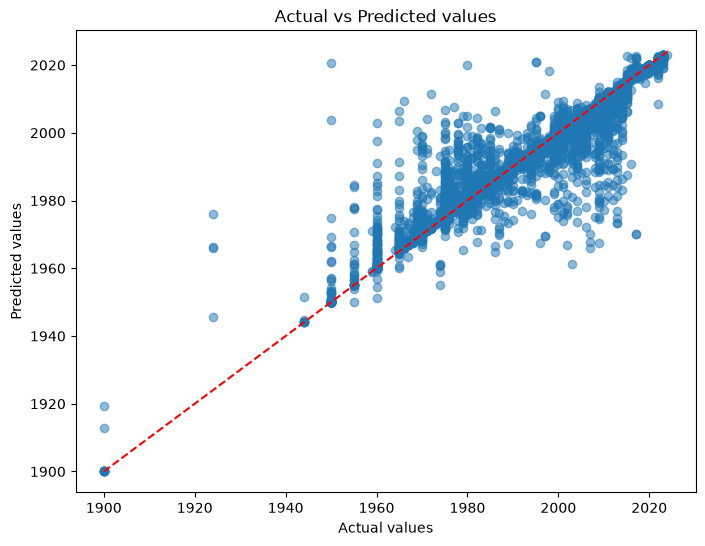

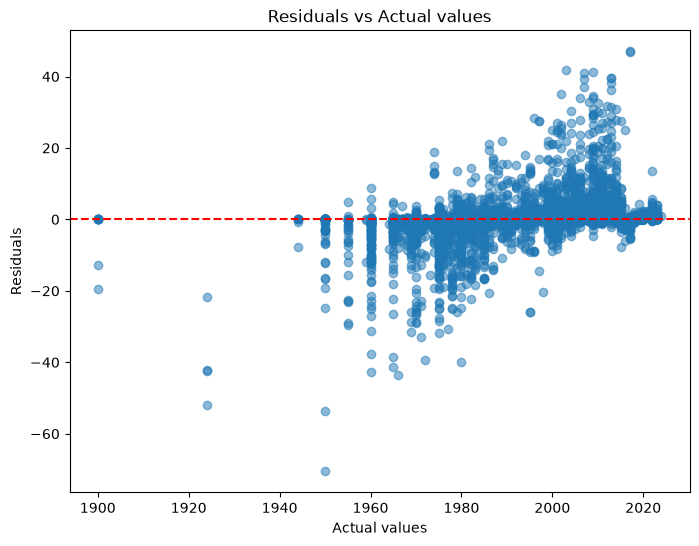

In [59]:
model = model_random_forest

y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

# Visualisation of predictions.

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_test, alpha=0.5)

# Línea de predicción perfecta
plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()], 'r--')

plt.xlabel('Actual values')
plt.ylabel('Predicted values')
plt.title('Actual vs Predicted values')
plt.show()

# Visualisation of residuals.
residuals = y_test - y_pred_test
plt.figure(figsize=(8, 6))
plt.scatter(y_test, residuals, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Actual values')
plt.ylabel('Residuals')
plt.title('Residuals vs Actual values')
plt.show()



## [OPTIONAL] 7.Feature Importance

Using the random forest, how can we determine which features are the most important?

# Code. In your opinion, how is feature importance calculated in Random Forest?

    Gini importance is derived from the Random Forest algorithm’s internal structure.
    It measures how much each feature contributes to reducing impurity in decision trees.


In [62]:
importances = model_random_forest.named_steps['regression'].feature_importances_
importances

array([3.30904850e-03, 8.87866625e-03, 9.02563165e-03, 1.78210569e-03,
       7.77878719e-06, 2.15909316e-05, 5.94283284e-05, 1.34951927e-03,
       1.11710073e-04, 7.79624788e-05, 1.53204743e-04, 1.29644169e-05,
       1.27948620e-04, 3.13560711e-07, 5.00722304e-05, 2.66865413e-07,
       3.68289257e-04, 2.95205451e-06, 1.13764958e-03, 6.55776117e-06,
       6.81201009e-06, 7.84687452e-05, 9.21150580e-05, 6.60557613e-05,
       0.00000000e+00, 9.93712858e-06, 3.26186745e-08, 0.00000000e+00,
       2.47457004e-08, 1.46589971e-06, 1.59972845e-05, 1.11554281e-04,
       2.04212121e-04, 7.19677068e-05, 3.51120275e-04, 8.81976561e-06,
       6.78222309e-06, 4.46940848e-04, 1.43028467e-04, 4.98549136e-04,
       1.30172562e-04, 2.13394494e-05, 1.42159072e-04, 1.25478455e-03,
       3.09442451e-05, 4.76891230e-06, 3.65556907e-06, 1.76745198e-04,
       4.48526720e-04, 1.58686180e-04, 1.81520864e-03, 2.14717838e-05,
       1.81327881e-05, 1.86968501e-05, 1.01128585e-04, 7.05236726e-06,
      

In [72]:
categorical_features = model_random_forest.named_steps['preprocessor'].transformers_[0][1].get_feature_names_out()
numerical_features = model_random_forest.named_steps['preprocessor'].transformers_[1][1].get_feature_names_out()
print("Categorical Features:", categorical_features)
print("Numerical Features:", numerical_features)
feature_names = list(categorical_features) + list(numerical_features)
print(len(feature_names), len(importances))


Categorical Features: ["sous_categorie_desc_Arbre d'enceintes fermées"
 "sous_categorie_desc_Arbre d'espaces ouverts"
 'sous_categorie_desc_Arbre de voirie'
 'sous_categorie_desc_Bois semi naturel'
 'code_parent_desc_A DL Weill Arménie à Esclangon'
 'code_parent_desc_A F Viallet la Gare à Jaures'
 'code_parent_desc_Al Romantiques Musset LBruyère'
 'code_parent_desc_All Deux Mondes aire de jeux'
 'code_parent_desc_All Romantiques LBruyère Vigny'
 'code_parent_desc_Allée Vaucanson' "code_parent_desc_Allée d'Essen"
 'code_parent_desc_Allée des Romantiques impair'
 'code_parent_desc_Allée des Romantiques pair'
 'code_parent_desc_Alpexpo park' 'code_parent_desc_Alpexpo park Eybens'
 'code_parent_desc_Arrèt tram La Bruyère Est'
 'code_parent_desc_Av A Belgique Perrot Cornier'
 'code_parent_desc_Av Bossuet Helbronner Racine'
 'code_parent_desc_Av Constantine park Cascateles'
 'code_parent_desc_Av Europe ech Constantin talus'
 'code_parent_desc_Av J O Valles Poterne sép'
 'code_parent_desc_Av 

                                            Feature  Gini Importance
475               stadededeveloppement_Arbre adulte         0.297405
477         stadededeveloppement_Arbre vieillissant         0.092539
550                                        latitude         0.092284
551                                       longitude         0.089681
500                      raisondeplantation_Unknown         0.045940
..                                              ...              ...
58               code_parent_desc_Butte n 04 zénith         0.000000
165    code_parent_desc_Prc La Bruyère mail central         0.000000
108  code_parent_desc_Jard Hoche Sud couronne extér         0.000000
498                         raisondeplantation_Rare         0.000000
489        remarques_PLANTATION 2015 PAR ENTREPRISE         0.000000

[552 rows x 2 columns]


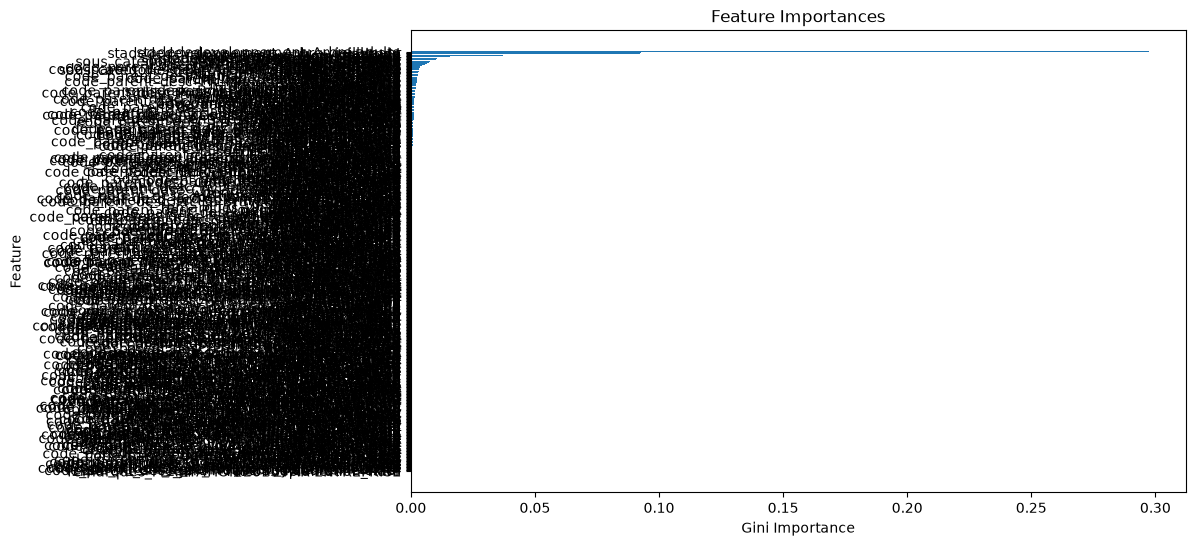

In [73]:

feature_imp_df = pd.DataFrame({'Feature': feature_names, 'Gini Importance': importances}).sort_values(
    'Gini Importance', ascending=False)
print(feature_imp_df)

# Visualisation of feature importances.
plt.figure(figsize=(10, 6))
plt.barh(feature_imp_df['Feature'], feature_imp_df['Gini Importance'])
plt.xlabel('Gini Importance')
plt.ylabel('Feature')
plt.title('Feature Importances')
plt.gca().invert_yaxis()
plt.show()


In [74]:

# break down feature importances by category if needed.
categorical_features = model_random_forest.named_steps['preprocessor'].transformers_[0][1].get_feature_names_out()
numerical_features = model_random_forest.named_steps['preprocessor'].transformers_[1][1].get_feature_names_out()
print("Categorical Features:", categorical_features)
print("Numerical Features:", numerical_features)


Categorical Features: ["sous_categorie_desc_Arbre d'enceintes fermées"
 "sous_categorie_desc_Arbre d'espaces ouverts"
 'sous_categorie_desc_Arbre de voirie'
 'sous_categorie_desc_Bois semi naturel'
 'code_parent_desc_A DL Weill Arménie à Esclangon'
 'code_parent_desc_A F Viallet la Gare à Jaures'
 'code_parent_desc_Al Romantiques Musset LBruyère'
 'code_parent_desc_All Deux Mondes aire de jeux'
 'code_parent_desc_All Romantiques LBruyère Vigny'
 'code_parent_desc_Allée Vaucanson' "code_parent_desc_Allée d'Essen"
 'code_parent_desc_Allée des Romantiques impair'
 'code_parent_desc_Allée des Romantiques pair'
 'code_parent_desc_Alpexpo park' 'code_parent_desc_Alpexpo park Eybens'
 'code_parent_desc_Arrèt tram La Bruyère Est'
 'code_parent_desc_Av A Belgique Perrot Cornier'
 'code_parent_desc_Av Bossuet Helbronner Racine'
 'code_parent_desc_Av Constantine park Cascateles'
 'code_parent_desc_Av Europe ech Constantin talus'
 'code_parent_desc_Av J O Valles Poterne sép'
 'code_parent_desc_Av 

In [85]:

# break down feature importance in categories so that we have all variables that are types of the same variable one below the other, i.e
# all variables with staded categories should be grouped together.

cat_importances_sorted = cat_importances.sort_values('Feature')
num_importances_sorted = num_importances.sort_values('Feature')

print("Categorical Feature Importances (Grouped):")
print(cat_importances_sorted)

# then compute average importances for each staded category, e.g. all variables with the same base name before the underscore, and do the average on the Gini importance.

cat_importances_grouped = cat_importances_sorted.groupby(cat_importances_sorted['Feature'].str.split('_').str[0])['Gini Importance'].mean()
num_importances_grouped = num_importances_sorted.groupby(num_importances_sorted['Feature'].str.split('_').str[0])['Gini Importance'].mean()

print("Numerical Feature Importances (Grouped):")
print(num_importances_grouped)

print("Categorical Feature Importances (Grouped and Averaged):")
print(cat_importances_grouped.sort_values(ascending=False))
print("\nNumerical Feature Importances (Grouped and Averaged):")
print(num_importances_grouped.sort_values(ascending=False))


Categorical Feature Importances (Grouped):
                      Feature  Gini Importance
274             adr_secteur_1         0.002191
275             adr_secteur_2         0.003677
276             adr_secteur_3         0.002498
277         adr_secteur_38151         0.000038
278         adr_secteur_38249         0.000031
..                        ...              ...
470  variete_Schwedleri nigra         0.000018
471  variete_Sunset boulevard         0.000006
472           variete_Unknown         0.001627
473     variete_Vallis clausa         0.000002
474            variete_Wierii         0.000648

[550 rows x 2 columns]
Numerical Feature Importances (Grouped):
Feature
latitude     0.092284
longitude    0.089681
Name: Gini Importance, dtype: float64
Categorical Feature Importances (Grouped and Averaged):
Feature
stadededeveloppement     0.103200
raisondeplantation       0.011681
hauteurarbre             0.010782
sous                     0.005749
structure                0.002522
adr 

In [98]:
# code et remarque ne sont pas tres predictifs --> voyons si on ameliore en les droppant
df = pd.read_pickle('arbres_clean_Alexia.pkl')
df.head()
#drop missing annee de plantation
df_dropped = df.dropna(subset=['anneedeplantation'])
df_dropped = df_dropped.drop(columns=['code_parent_desc', 'remarques'])
df_dropped.head()


,sous_categorie_desc,adr_secteur,genre_bota,espece,variete,stadededeveloppement,anneedeplantation,raisondeplantation,traitementchenilles,identifiantplu,...,intituleprotectionplu,collectivite,stationmetro,hauteurarbre,portarbre,structure,forme,typenature,latitude,longitude
0,Arbre de voirie,5,Prunus,serrulata,Unknown,Arbre jeune,2015.0,Nouveau,Unknown,Unknown,...,Unknown,Grenoble Alpes Métropole,Unknown,Unknown,Unknown,Métropole de Grenoble,Unknown,Unknown,45.167098,5.740132
1,Arbre de voirie,5,Prunus,serrulata,Unknown,Arbre jeune,2015.0,Nouveau,Unknown,Unknown,...,Unknown,Grenoble Alpes Métropole,Unknown,Unknown,Unknown,Métropole de Grenoble,Unknown,Unknown,45.167107,5.740200
2,Arbre de voirie,5,Prunus,serrulata,Unknown,Arbre jeune,2015.0,Nouveau,Unknown,Unknown,...,Unknown,Grenoble Alpes Métropole,Unknown,Unknown,Unknown,Métropole de Grenoble,Unknown,Unknown,45.167115,5.740266
3,Arbre de voirie,5,Prunus,serrulata,Unknown,Arbre jeune,2015.0,Nouveau,Unknown,Unknown,...,Unknown,Grenoble Alpes Métropole,Unknown,Unknown,Unknown,Métropole de Grenoble,Unknown,Unknown,45.167127,5.740349
4,Arbre de voirie,5,Prunus,serrulata,Unknown,Arbre jeune,2015.0,Nouveau,Unknown,Unknown,...,Unknown,Grenoble Alpes Métropole,Unknown,Unknown,Unknown,Métropole de Grenoble,Unknown,Unknown,45.167144,5.740471


In [99]:

# do new train-test split without 'code' and 'remarques'
X = df_dropped.drop(columns=['anneedeplantation'])
y = df_dropped['anneedeplantation']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [103]:
categorical_variables = X_train.select_dtypes(
    include=['object', 'string', 'category']
).columns.tolist()

numerical_variables = X_train.select_dtypes(include = ['number']).columns.tolist()
print(categorical_variables,numerical_variables)

#pipeline
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))])

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

preprocessor = ColumnTransformer([
    ('cat', categorical_pipeline, categorical_variables),
    ('num', numerical_pipeline, numerical_variables)])

model_random_forest = RandomForestRegressor(random_state=42)
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', model_random_forest)
])
model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)


['sous_categorie_desc', 'adr_secteur', 'genre_bota', 'espece', 'variete', 'stadededeveloppement', 'raisondeplantation', 'traitementchenilles', 'identifiantplu', 'typeimplantationplu', 'intituleprotectionplu', 'collectivite', 'stationmetro', 'hauteurarbre', 'portarbre', 'structure', 'forme', 'typenature'] ['latitude', 'longitude']


In [104]:
# mesures de performance
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error as root_mean_squared_error    

print("Train RMSE:", root_mean_squared_error(y_train, y_pred_train))
print("Train MAE:", mean_absolute_error(y_train, y_pred_train))
print("Train R2:", r2_score(y_train, y_pred_train))

print("Test RMSE:", root_mean_squared_error(y_test, y_pred_test))
print("Test MAE:", mean_absolute_error(y_test, y_pred_test))
print("Test R2:", r2_score(y_test, y_pred_test))

Train RMSE: 4.1577405461473305
Train MAE: 0.7660410668924601
Train R2: 0.9874734206008716
Test RMSE: 28.409905807653256
Test MAE: 2.10052658313579
Test R2: 0.912254762374997


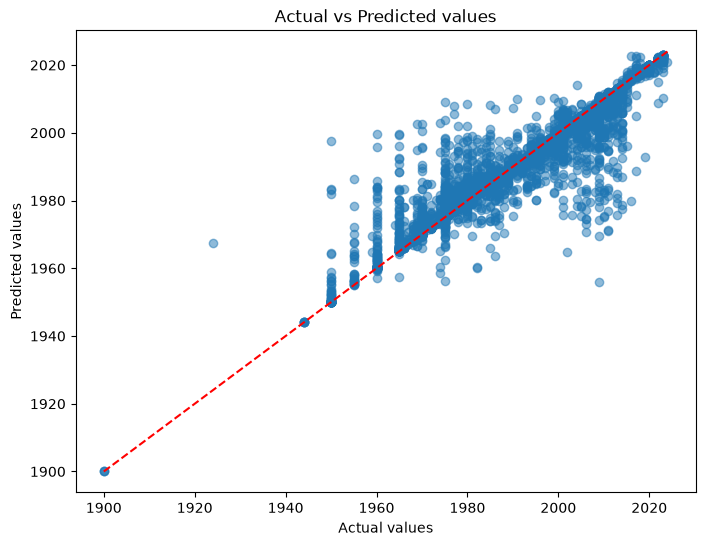

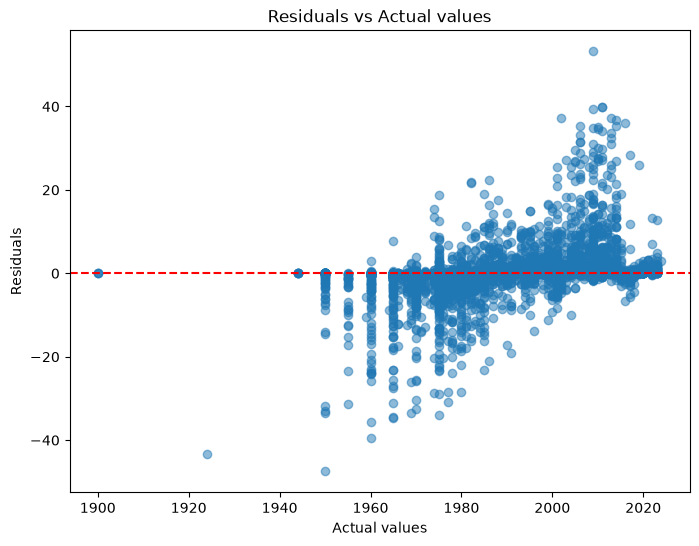

In [ ]:


# Visualisation of predictions.

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_test, alpha=0.5)

# Línea de predicción perfecta
plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()], 'r--')

plt.xlabel('Actual values')
plt.ylabel('Predicted values')
plt.title('Actual vs Predicted values')
plt.show()

# Visualisation of residuals.
residuals = y_test - y_pred_test
plt.figure(figsize=(8, 6))
plt.scatter(y_test, residuals, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Actual values')
plt.ylabel('Residuals')
plt.title('Residuals vs Actual values')
plt.show()



Typically, one might consider using backward elimination on feature importance to select the best subset of features, but this can be time-consuming if there are many features and the model takes a while to train, as is the case here. Instead, we can use Lasso-regularized regression to eliminate features, before retraining a RandomForest on the selected features. Create a pipeline with `LassoCV` as the selector and a RandomForest as the model with the best hyperparameters found by the previous grid-search. Evaluate on the test set.

In [ ]:
# Code

## 8. [OPTIONAL]  Compare more different models

Compare more regression models with one another (for example, in addition to linear regression, decision trees, and forests, use `GradientBoostingRegressor`, and the novel `TabICLRegressor` if you have time ( https://github.com/soda-inria/tabicl ))), by performing appropriate hyperparameter tuning for each model:

In [ ]:
# Code. Search which hyper-parameters are worth tuning for each model

Choose the model that performs best and its optimal hyperparameters, then select the best subset of features for this model, and finally perform one last grid search on your model’s hyperparameters using the selected features to obtain your final model. Evaluate it on the test set.

In [ ]:
# Code

## Conclusion